# Jet fuel hedge risk: from EIA to reporting

Run from the repository root using the locked project environment. This notebook captures actual EIA data if no completed local capture exists, rebuilds Silver, calibrates weekly EWM GBM, and reproduces 100,000 common price paths and five hedge scenarios. The production distributed implementation and live verification commands are linked below.

Credentials belong in Git-ignored `.env`; nothing in this notebook contains credentials. Actual prices are EIA Gulf Coast jet fuel; operations are explicitly synthetic. The reference carrier consumes 1.5 billion gallons/year. This is a simplified spot/financing-carry model, with no options, basis-risk, margin/liquidity or optimal-hedge claim.

In [1]:
from pathlib import Path
import json
from datetime import date,timedelta
import numpy as np
from fuel_hedge.config import load_env,Settings
from fuel_hedge.eia import EIAClient
from fuel_hedge.bronze import capture,read_completed
from fuel_hedge.silver import build_silver,weekly_prices
from fuel_hedge.operations import synthetic_operations
from fuel_hedge.simulation import SimulationConfig,calibrate,price_paths,cost_distribution,risk_summary
assert Path('pyproject.toml').exists(), 'Start Jupyter from the repository root'
load_env()
settings=Settings.from_env()
refresh_source=False  # Set True to append a fresh full-history capture.
root=Path('artifacts/bronze')
if refresh_source or not list((root/'manifests').glob('*.json')):
    capture(EIAClient(settings.eia_api_key),'2010-01-01',(date.today()-timedelta(days=1)).isoformat(),root)
events=read_completed(root)
print('Completed actual EIA page events:',len(events))

Completed actual EIA page events: 4


## Silver: revision-aware daily prices and complete weekly samples

Latest revisions win, including withdrawals. Optional proxies stay null. WTI USD/barrel is divided by 42 for crack spreads. Daily volatility uses a calendar window and suppresses long gaps; simulation uses regular weekly returns with its own annualization.

In [2]:
daily,quarantine=build_silver(events)
weekly=weekly_prices(daily)
output=Path('artifacts/silver')
output.mkdir(parents=True,exist_ok=True)
daily.to_csv(output/'fuel_prices.csv',index=False)
weekly.to_csv(output/'weekly_fuel_prices.csv',index=False)
print('Daily rows:',len(daily),'weekly rows:',len(weekly),'quarantined rows:',len(quarantine))
print(daily[['price_date','jet_fuel_gal','wti_spot_bbl','crack_spread']].tail().to_string(index=False))
fixtures=synthetic_operations(daily.price_date.max().date())
print('Synthetic routes:',len(fixtures['routes']),'scheduled flights:',len(fixtures['flights']))

Daily rows: 4213 weekly rows: 874 quarantined rows: 0
price_date  jet_fuel_gal  wti_spot_bbl  crack_spread
2026-09-30         4.677         97.18      2.363190
2026-10-01         4.355         99.77      1.979524
2026-10-02         4.307         97.89      1.976286
2026-10-05         4.350         96.13      2.061190
2026-10-06         4.342         96.24      2.050571
Synthetic routes: 8 scheduled flights: 8395


## Weekly calibration and exact GBM transition

For weekly log returns $x_t$, normalize weights $w_t\propto0.94^{n-1-t}$. Let $m=\sum w_tx_t$ and $v=\sum w_t(x_t-m)^2/(1-\sum w_t^2)$. Then $\sigma=\sqrt{52v}$ and $\mu=52m+\sigma^2/2$.

Simulate $S_{t+\Delta t}=S_t\exp[(\mu-\sigma^2/2)\Delta t+\sigma\sqrt{\Delta t}Z]$ with Box–Muller normals. Each path has a SeedSequence(base seed,path ID), so repartitioning does not change it. The most recent daily price is S0. Historical drift is not a risk-neutral forecast and can be highly unstable.

In [3]:
calibration=calibrate(weekly)
config=SimulationConfig(s0=float(daily.sort_values('price_date').jet_fuel_gal.iloc[-1]),
    mu=calibration['mu'],sigma=calibration['sigma'],n_paths=100_000,seed=20261010)
print(json.dumps(calibration,indent=2))
paths=price_paths(np.arange(config.n_paths),config)
costs=cost_distribution(paths,config)
risk=risk_summary(costs)
print('Paths:',paths.shape,'forward USD/gallon:',round(config.forward_price,6))
print(risk.round(6).to_string(index=False))

{
  "mu": 0.9291402579710721,
  "sigma": 0.6050536840108929,
  "decay": 0.94,
  "n_returns": 52,
  "calibration_start": "2025-10-03",
  "calibration_end": "2026-10-02",
  "weekly_log_mean": 0.014347986109682603,
  "weekly_log_variance": 0.007040191548752949
}
Paths: (100000, 53) forward USD/gallon: 4.5192
 hedge_ratio  mean_cost_b  p50_cost_b  p95_cost_b  var_95_b  cvar_95_b  n_paths  var_reduction_pct
         0.0    10.827796    9.924485    19.28300  8.455204  23.457696   100000                0.0
         0.2    10.017997    9.295348    16.78216  6.764163  20.121917   100000               20.0
         0.4     9.208198    8.666211    14.28132  5.073122  16.786138   100000               40.0
         0.6     8.398399    8.037074    11.78048  3.382082  13.450359   100000               60.0
         0.8     7.588600    7.407937     9.27964  1.691041  10.114580   100000               80.0


## Tail metrics and scenario interpretation

Use future weekly purchase prices, excluding S0. Cost is $G T[hS_0e^{rT}+(1-h)\bar S]/10^9$. P95 is the absolute 95th percentile; incremental VaR = P95 − mean; CVaR is the average cost at/above absolute P95. All monetary risk metrics are USD billions.

With identical paths and fixed forward, scenario costs are an affine transformation of unhedged costs. Incremental VaR reduction equals hedge coverage by construction. It does not prove that 80% is the right hedge for an airline. Lower prices create hedge opportunity costs, shown in the sensitivity grid.

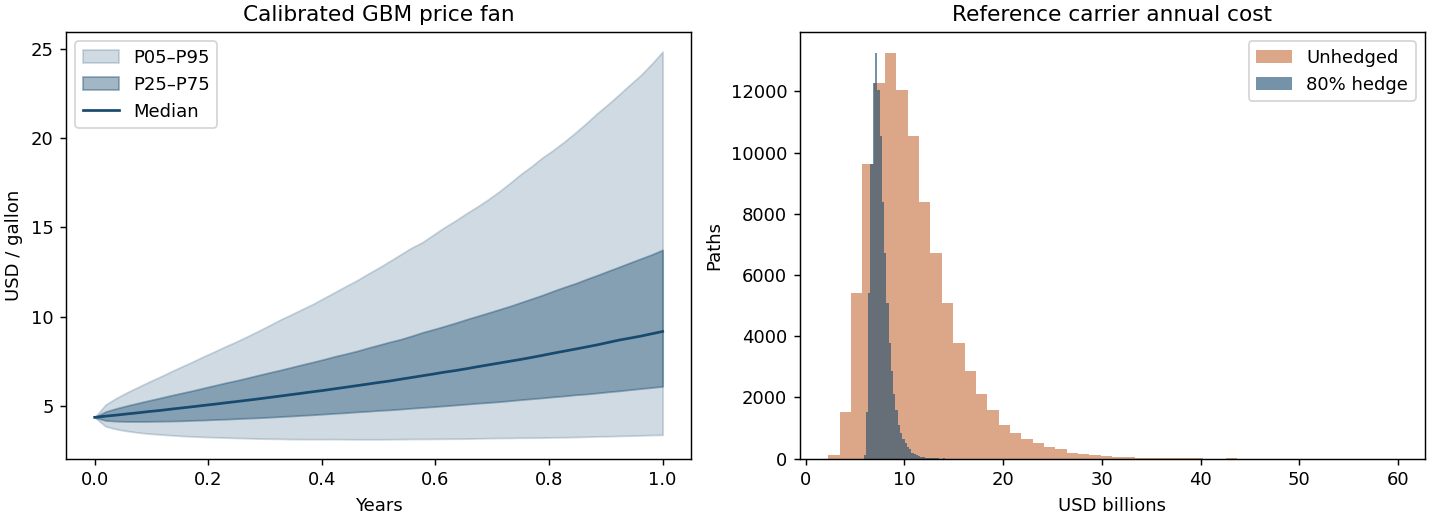

In [4]:
import matplotlib.pyplot as plt
fan=np.quantile(paths,[.05,.25,.5,.75,.95],axis=0)
years=np.arange(config.steps+1)/52
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].fill_between(years,fan[0],fan[4],alpha=.2,color='#174a6e',label='P05–P95')
axes[0].fill_between(years,fan[1],fan[3],alpha=.4,color='#174a6e',label='P25–P75')
axes[0].plot(years,fan[2],color='#174a6e',label='Median')
axes[0].set(title='Calibrated GBM price fan',xlabel='Years',ylabel='USD / gallon')
axes[0].legend()
axes[1].hist(costs[0.0],bins=50,alpha=.6,label='Unhedged',color='#c66c39')
axes[1].hist(costs[.8],bins=50,alpha=.6,label='80% hedge',color='#174a6e')
axes[1].set(title='Reference carrier annual cost',xlabel='USD billions',ylabel='Paths')
axes[1].legend()
plt.show()

## Production deployment and independent verification

From a shell at the repository root:
```powershell
uv run python scripts/deploy_phase1.py --wait
uv run python scripts/deploy_phase2.py
# Wait for each remote job to succeed before submitting the next phase.
uv run python scripts/deploy_phase3.py
uv run python scripts/verify_phase1.py
uv run python scripts/verify_phase2.py
uv run python scripts/verify_phase3.py
```
The managed daily job executes sequentially and finishes by publishing guarded reporting views. See `docs/RUNBOOK.md` for deployment/scheduling and `docs/POWER_BI.md` for connection, grains and measures. `dashboard/plots/provenance.json` records independently verified live evidence; this notebook's local execution is separate evidence. Read `docs/PLAN.md` and `CHANGELOG.md` before continuing development.